#Exploratory Data Analysis

This dataset is composed by 5000 CVs...

In [75]:
!pip3 install pandas
!pip install adjustText

In [76]:
import json
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
from utils.path_loader import load_paths
from sklearn.cluster import KMeans
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from adjustText import adjust_text
import networkx as nx
import shutil
import os


In [77]:


def readfiles(raw_data_path):
    raw_path = Path(raw_data_path)
    texts = []
    annotations_ = []

    for json_file in raw_path.rglob("*.json"):
        with open(json_file, 'r', encoding='utf-8', errors='replace') as f:
            data = json.load(f)
            
            text = data.get("text", "")
            
            # Clean lone surrogates that crash PyArrow/Pandas
            if isinstance(text, str):
                text = text.encode("utf-8", "surrogatepass").decode("utf-8", "ignore")
            
            annotations = data.get("annotations", [])

            texts.append(text)
            annotations_.append(annotations)
            
    df_skills = pd.DataFrame({"text": texts, "annotations": annotations_})
    return df_skills

Remover Cvs em branco

In [78]:
# 1. Garante que valores nulos (NaN) são tratados como strings vazias
df_skills['text'] = df_skills['text'].fillna('')

# 2. Remove os CVs onde o texto está vazio ou contém apenas espaços/quebras de linha
df_skills = df_skills[df_skills['text'].str.strip() != '']

# 3. (Opcional) Se quiser verificar quantos foram removidos
print(f"Número de CVs após a limpeza: {len(df_skills)}")

Número de CVs após a limpeza: 4971


In [79]:
df_skills = readfiles("data/raw/Json")

In [80]:
df_skills.head()

,text,annotations
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL..."
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ..."
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK..."
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI..."
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI..."


In [81]:
df_skills["annotations"][0:2].tolist()

[[[657, 665, 'SKILL: Building'],
  [822, 828, 'SKILL: python'],
  [811, 815, 'SKILL: java'],
  [781, 790, 'SKILL: Knowledge'],
  [877, 887, 'SKILL: Processing'],
  [194, 205, 'SKILL: performance'],
  [442, 452, 'SKILL: Technology'],
  [1007, 1014, 'SKILL: PySpark'],
  [30, 44, 'SKILL: Data Scientist'],
  [153, 162, 'SKILL: Detection'],
  [329, 345, 'SKILL: computer science'],
  [102, 108, 'SKILL: Images'],
  [889, 902, 'SKILL: Deep Learning'],
  [942, 954, 'SKILL: data science'],
  [1031, 1037, 'SKILL: skills'],
  [1147, 1155, 'SKILL: Projects'],
  [734, 737, 'SKILL: CAN'],
  [575, 590, 'SKILL: Market Research'],
  [956, 969, 'SKILL: Data Analysis'],
  [904, 919, 'SKILL: Computer Vision'],
  [802, 809, 'SKILL: Process'],
  [817, 818, 'SKILL: C'],
  [164, 167, 'SKILL: OCR'],
  [604, 612, 'SKILL: Analysis'],
  [838, 846, 'SKILL: Learning'],
  [971, 988, 'SKILL: Software Engineer'],
  [338, 345, 'SKILL: Science'],
  [267, 278, 'SKILL: Probability'],
  [772, 780, 'SKILL: Exchange'],
  [379

In [82]:
def extract_skills(annotation_list):
    # This list comprehension pulls the string from index 2 of each sub-list
    return [item[2] for item in annotation_list]

# Create the new column
df_skills['skills_list'] = df_skills['annotations'].apply(extract_skills)

# Optional: If you want a single string separated by commas instead of a list:
# df_skills['skills_string'] = df_skills['skills_list'].apply(lambda x: ", ".join(x))

In [83]:
#Remover vazios
df_skills = df_skills[df_skills['skills_list'].apply(len) > 0].copy()

df_skills = df_skills.reset_index(drop=True)

print(f"Novo total de CVs: {len(df_skills)}")
print(df_skills.head())

Novo total de CVs: 4971
                                                text  \
0  One97 Communications Limited \nData Scientist ...   
1  Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...   
2  Yogesh Chandra Pandey Mobile: +91--7017692645\...   
3  ARUN KUMAR U.C.  \n \nMob :+91 9745004628     ...   
4  ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...   

                                         annotations  \
0  [[657, 665, SKILL: Building], [822, 828, SKILL...   
1  [[383, 389, SKILL: scikit], [338, 344, SKILL: ...   
2  [[298, 307, SKILL: reporting], [1218, 1234, SK...   
3  [[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...   
4  [[1089, 1099, SKILL: Test cases], [61, 66, SKI...   

                                         skills_list  
0  [SKILL: Building, SKILL: python, SKILL: java, ...  
1  [SKILL: scikit, SKILL: python, SKILL: Scikit l...  
2  [SKILL: reporting, SKILL: Business Studies, SK...  
3  [SKILL: WINDOWS XP, SKILL: Problem solving, SK...  
4  [SKILL: Test cases, SKIL

In [84]:
df_skills["num_annon"]=df_skills["skills_list"].apply(len)

<Axes: >

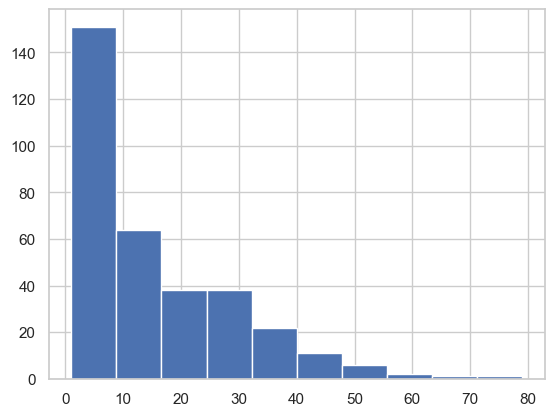

In [85]:
df_skills["num_annon"].value_counts().hist()

#Há uma tendência para os currículso terem, em média, 10 annotações.

In [86]:
unique_skills = df_skills["skills_list"].explode().unique().tolist()

In [87]:
len(unique_skills)

12695

In [88]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skills_list
SKILL: COM                     3874
SKILL: skills                  3805
SKILL: Work                    3679
SKILL: Personal                3458
SKILL: Knowledge               3417
                               ... 
SKILL: Governance Standards       1
SKILL: Emergency Medicine         1
SKILL: iHeart Radio               1
SKILL: Big Bang                   1
SKILL: Debugging skills           1
Name: count, Length: 12695, dtype: int64


In [89]:
df_skills[df_skills["skills_list"].apply(lambda x: "SKILL: COM" in x)]

,text,annotations,skills_list,num_annon
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[SKILL: reporting, SKILL: Business Studies, SK...",52
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[SKILL: Test cases, SKILL: GMail, SKILL: java,...",80
6,"\t\n\t\n\t\n\t\n\t\n\t\nBarbara Farman, Hair,...","[[787, 793, SKILL: Hunter], [1618, 1624, SKILL...","[SKILL: Hunter, SKILL: Health, SKILL: ADAMS, S...",36
7,"\n2632 La Cienega Avenue Los Angeles, C...","[[847, 853, SKILL: Hunter], [2447, 2451, SKILL...","[SKILL: Hunter, SKILL: COLA, SKILL: Australia,...",23
8,"\n \n \n \nBethany Newell, Manicurist \nwww.c...","[[968, 980, SKILL: Self service], [1799, 1805,...","[SKILL: Self service, SKILL: Forbes, SKILL: co...",21
...,...,...,...,...
4965,"\n \n \n \nDenika Bedrossian , Makeup Artist...","[[105, 109, SKILL: ADAM], [3504, 3512, SKILL: ...","[SKILL: ADAM, SKILL: Big Bang, SKILL: CAN, SKI...",38
4966,"\t\n\t\n\t\n\t\n \nDestinee Handly, Manicurist...","[[1283, 1289, SKILL: Sensor], [1305, 1310, SKI...","[SKILL: Sensor, SKILL: Music, SKILL: Advertisi...",12
4967,"\t\n\t\n\t\n \nDevon Nuszer, Wardrobe Stylist...","[[207, 211, SKILL: ADAM], [755, 758, SKILL: CA...","[SKILL: ADAM, SKILL: CAN, SKILL: Advertising, ...",8
4969,ResumeNitesh\nNITESH KUMAR\n Email id: niteshj...,"[[1876, 1885, SKILL: Inventory], [73, 78, SKIL...","[SKILL: Inventory, SKILL: GMail, SKILL: Knowle...",89


In [90]:
#Remover Prefixo "Skill"

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda x: [item.split(': ')[-1] if ': ' in item else item for item in x]
)

In [91]:
df_skills.head()

,text,annotations,skills_list,num_annon
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[Building, python, java, Knowledge, Processing...",70
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[scikit, python, Scikit learn, TensorFlow, Dee...",32
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[reporting, Business Studies, Managing, Maths,...",52
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[WINDOWS XP, Problem solving, Knowledge, Arts,...",42
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[Test cases, GMail, java, Knowledge, ASP, Crit...",80


In [92]:
df_skills["skills_list"].explode().value_counts()

skills_list
COM                             3874
skills                          3805
Work                            3679
Personal                        3458
Knowledge                       3417
                                ... 
Research Programs                  1
Continuing Medical Education       1
Big Bang                           1
iHeart Radio                       1
Debugging skills                   1
Name: count, Length: 12693, dtype: int64

In [93]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

def clean_skills_text(skills_list):
    stop_words = set(stopwords.words('english'))
    cleaned_list = []
    for skill in skills_list:

        words = skill.split()
        filtered_words = [w for w in words if w.lower() not in stop_words]
        cleaned_skill = " ".join(filtered_words).strip()
        if cleaned_skill:
            cleaned_list.append(cleaned_skill)
            
    return cleaned_list

df_skills['skills_list'] = df_skills['skills_list'].apply(clean_skills_text)

df_skills['skills_list'] = df_skills['skills_list'].apply(lambda x: list(set(x)))

In [94]:
#Remover skills genéricas e não relevantes
blacklist = {"COM", "Skills" , "personal","information", "knowledge", "process", "skills", "can", "work", "marital status", "nationality", "com", "languages", "board", "email", "qualification","activities"}

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: [s for s in lista if s.lower() not in blacklist]
)


In [95]:
#Normalizar

df_skills['skills_list'] = df_skills['skills_list'].apply(
    lambda lista: list(set([s.lower().strip() for s in lista]))
)

print(df_skills['skills_list'].head())

df_skills["skills_list"].explode().count()

0    [market research, performance, building, insur...
1    [parking, scikit learn, benefits, company, sys...
2    [tools, economics, handling, location, comment...
3    [ph, uc, interpersonal, business, internet, co...
4    [system testing, tools, regression, aggregate,...
Name: skills_list, dtype: object


np.int64(493902)

skills_list
english                  3399
gmail                    3238
project                  2683
professional             2661
hindi                    2636
                         ... 
communicable diseases       1
arterial blood gases        1
big bang                    1
iheart radio                1
debugging skills            1
Name: count, Length: 12569, dtype: int64


Text(0.5, 0, 'Skills names')

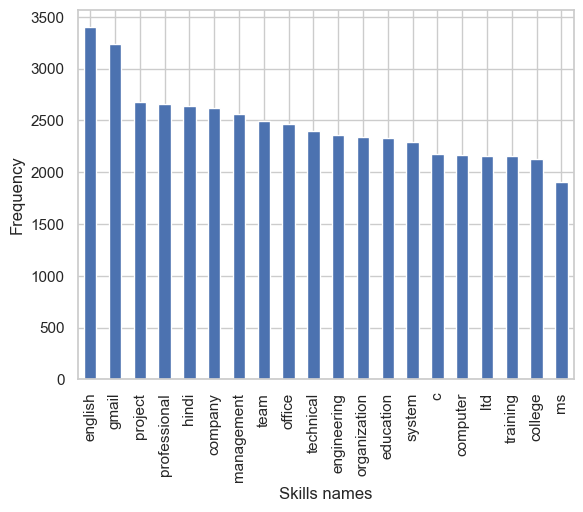

In [96]:
skill_counts = df_skills["skills_list"].apply(set).explode().value_counts()

print(skill_counts)

skill_counts.head(20).plot(kind='bar')
plt.ylabel('Frequency')
plt.xlabel('Skills names')
#Removemos conectores(e.g "is") e outras skills que não eram relevantes"

Qual será o tamanho médio dos CVs?

🔍 Analisando ficheiros em: C:\Users\duart\OneDrive\Documentos\GitHub\Capstone\data\raw\Json

--- Statistics ---
Total Number of CVs: 4971
Average Nº of characters: 4482.93
Min Nº of characters: 19
Max Nº of characters: 99973


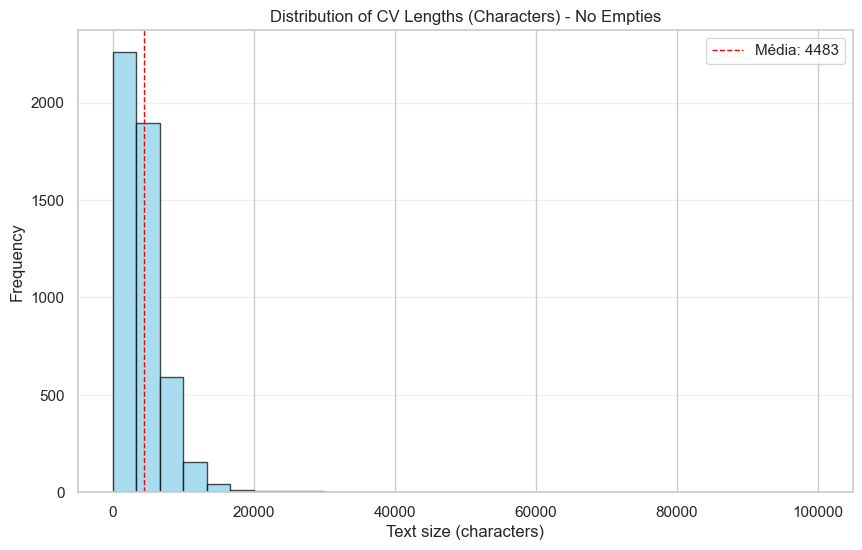

In [97]:
DATA_RAW = Path("data/raw/Json")

def analyze_cv_lengths():
    lengths = []
    file_count = 0

    print(f"🔍 Analisando ficheiros em: {DATA_RAW.resolve()}")

    for json_file in DATA_RAW.rglob("*.json"):
        try:
            data = json.loads(json_file.read_text(encoding="utf-8"))
            
            # Obtém o texto das chaves possíveis
            content = data.get("text") or data.get("content")
            
            # VERIFICAÇÃO DE VAZIOS:
            # 1. content is not None (existe a chave)
            # 2. isinstance(content, str) (é texto)
            # 3. content.strip() (não são apenas espaços ou \n)
            if content and isinstance(content, str) and content.strip():
                lengths.append(len(content))
                file_count += 1
                
        except Exception as e:
            print(f"❌ Erro ao ler {json_file.name}: {e}")

    if not lengths:
        print("⚠️ Nenhum dado válido encontrado após remover vazios.")
        return

    df = pd.DataFrame(lengths, columns=['length'])
    avg_len = df['length'].mean()

    print(f"\n--- Statistics ---")
    print(f"Total Number of CVs: 4971")
    print(f"Average Nº of characters: {avg_len:.2f}")
    print(f"Min Nº of characters: {df['length'].min()}")
    print(f"Max Nº of characters: {df['length'].max()}")

    # Gráfico
    plt.figure(figsize=(10, 6))
    plt.hist(lengths, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    plt.axvline(avg_len, color='red', linestyle='dashed', linewidth=1, label=f'Média: {avg_len:.0f}')
    
    plt.title('Distribution of CV Lengths (Characters) - No Empties')
    plt.xlabel('Text size (characters)')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    
    plt.savefig("eda_tamanho_cvs.png")
    plt.show()

if __name__ == "__main__":
    analyze_cv_lengths()

Quantas skills por CV

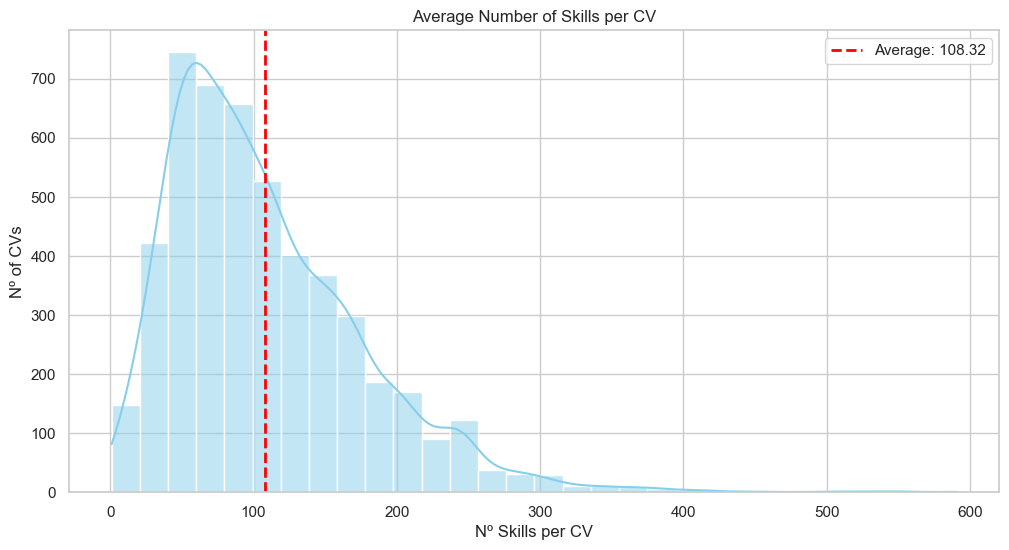

In [98]:

media_skills = df_skills['num_annon'].mean()

plt.figure(figsize=(12, 6))
sns.histplot(df_skills['num_annon'], bins=30, kde=True, color='skyblue')
plt.axvline(media_skills, color='red', linestyle='--', linewidth=2, label=f'Average: {media_skills:.2f}')

plt.title('Average Number of Skills per CV')
plt.xlabel('Nº Skills per CV')
plt.ylabel('Nº of CVs')
plt.legend()
plt.show()

In [99]:
def check_duplicate_skills(row):
    skills = row['skills_list']
    
    # Garante que é uma lista e não está vazia
    if isinstance(skills, list) and len(skills) > 0:
        # Se o tamanho do set for menor que a lista, há duplicados
        if len(set(skills)) < len(skills):
            # Encontrar quais são as repetidas
            seen = set()
            duplicates = [s for s in skills if s in seen or seen.add(s)]
            return list(set(duplicates))
    return None

# Criar uma nova coluna para identificar duplicados
df_skills['duplicated_skills'] = df_skills.apply(check_duplicate_skills, axis=1)

# Filtrar apenas os CVs que têm repetidos para ver o resultado
cvs_com_repetidos = df_skills[df_skills['duplicated_skills'].notnull()]

if not cvs_com_repetidos.empty:
    print(f"⚠️ Encontrados {len(cvs_com_repetidos)} CVs com skills repetidas.")
    print(cvs_com_repetidos[['skills_list', 'duplicated_skills']].head())
else:
    print("✅ Não foram encontradas skills repetidas em nenhum CV.")

✅ Não foram encontradas skills repetidas em nenhum CV.


Será que existem skills relacionadas?

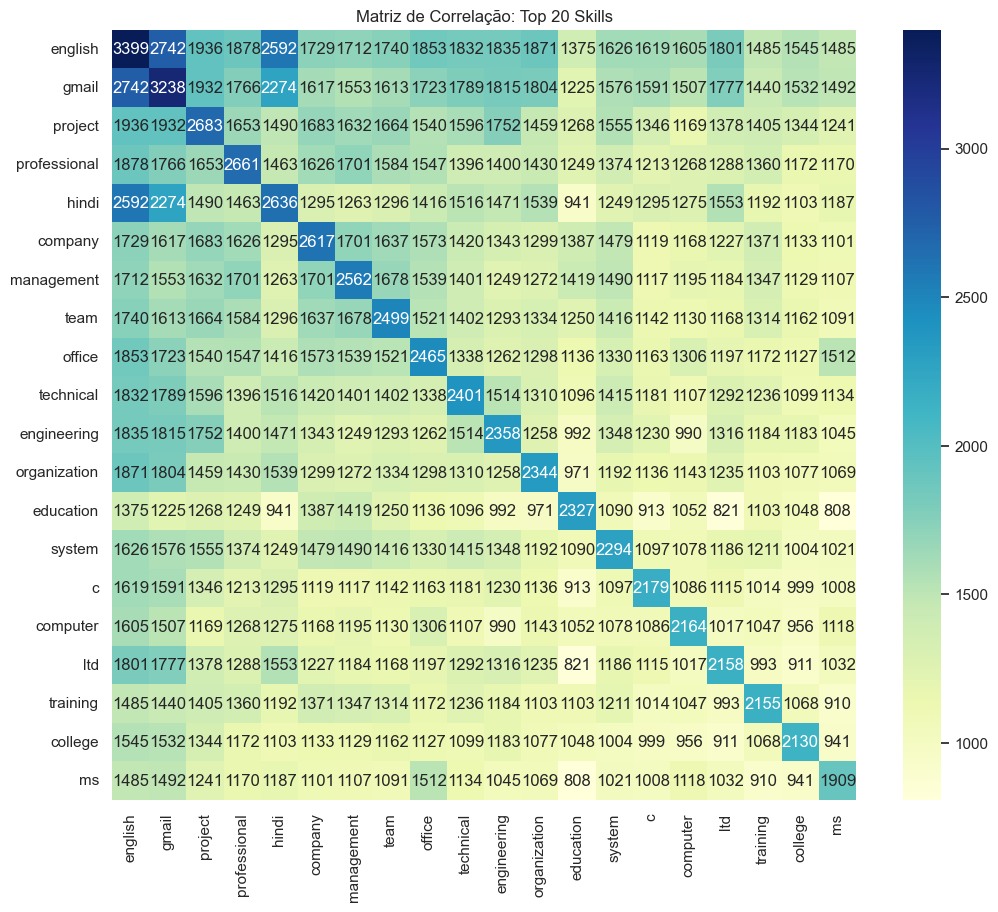

In [100]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
skills_encoded = pd.DataFrame(mlb.fit_transform(df_skills['skills_list']), 
                             columns=mlb.classes_, 
                             index=df_skills.index)

top_20_skills = df_skills['skills_list'].explode().value_counts().head(20).index
subset_encoded = skills_encoded[top_20_skills]

co_occurrence_matrix = subset_encoded.T.dot(subset_encoded)

plt.figure(figsize=(12, 10))
sns.heatmap(co_occurrence_matrix, annot=True, fmt="d", cmap="YlGnBu")
plt.title('Matriz de Correlação: Top 20 Skills')
plt.show()

E quais são as mais raras?

In [101]:
threshold_pct = 1

total_cvs = len(df_skills)
skills_per_cv = df_skills['skills_list'].apply(lambda x: list(set(x)) if isinstance(x, list) else [])
individual_cv_counts = skills_per_cv.explode().value_counts()
individual_pct = (individual_cv_counts / total_cvs) * 100

rare_skills = individual_pct[individual_pct < threshold_pct]
count_rare = len(rare_skills)
total_unique_skills = len(individual_pct)
perc_representation = (count_rare / total_unique_skills) * 100 if total_unique_skills > 0 else 0

print(f"Limiar definido: < {threshold_pct}%")
print(f"Nº de skills raras: {count_rare}")
print(f"Percentagem do total de skills únicas: {perc_representation:.2f}%")

Limiar definido: < 1%
Nº de skills raras: 11069
Percentagem do total de skills únicas: 88.07%


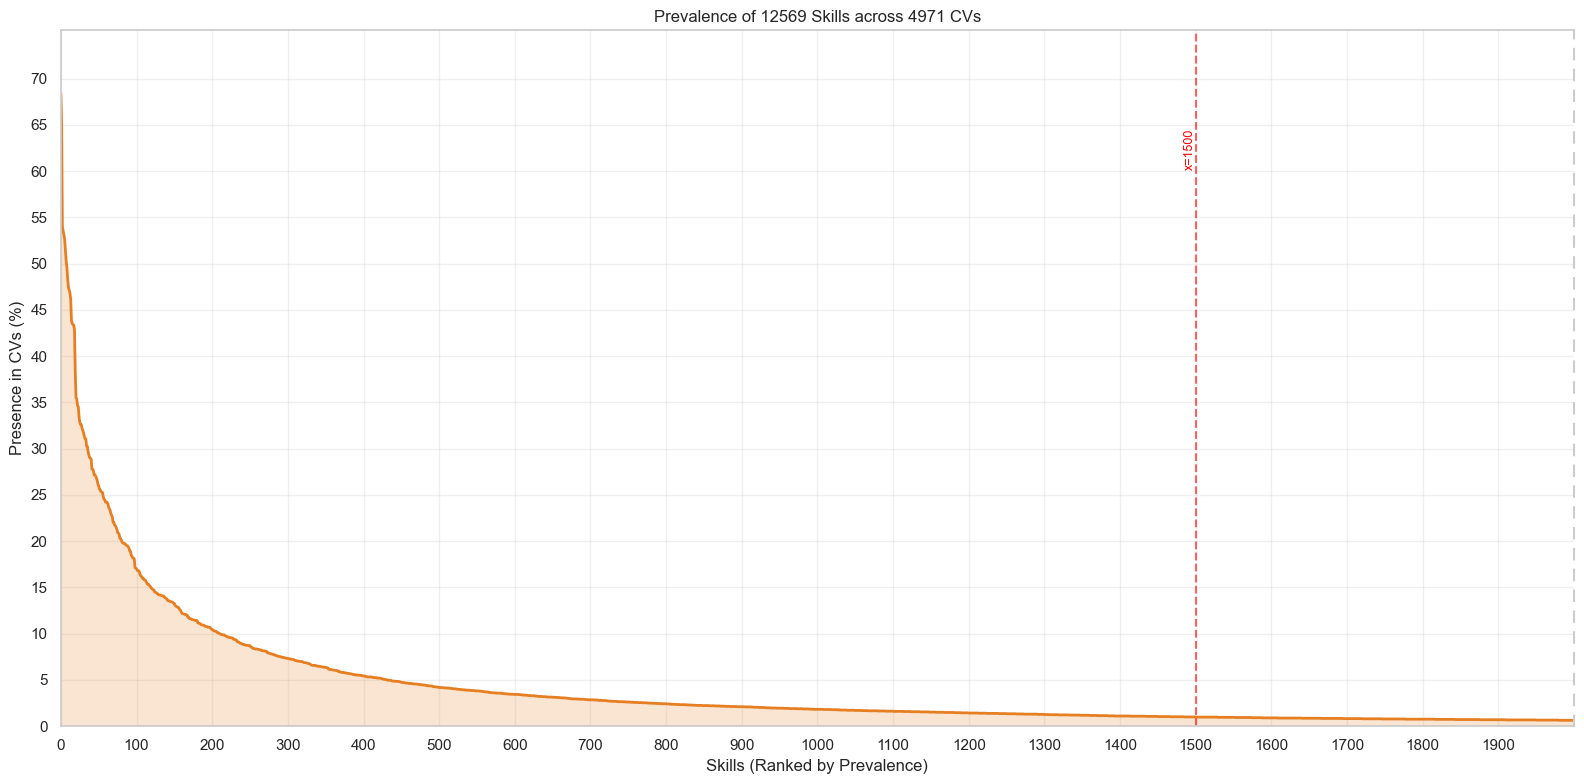

In [102]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Calcular a presença da skill por CV (Frequência Documental)
# Aplicamos unique() em cada lista para não contar skills repetidas no mesmo CV
total_cvs = len(df_skills)
skills_per_cv = df_skills['skills_list'].apply(lambda x: list(set(x)) if isinstance(x, list) else [])

# 2. Contar em quantos CVs cada skill aparece e converter para percentagem
individual_cv_counts = skills_per_cv.explode().value_counts()
individual_pct = (individual_cv_counts / total_cvs) * 100

y_values = individual_pct.values
x_values = np.arange(len(y_values))

fig, ax = plt.subplots(figsize=(16, 8))

# Plot principal
ax.plot(x_values, y_values, color='#e67e22', linewidth=2)
ax.fill_between(x_values, y_values, color='#e67e22', alpha=0.2)

# 1. Linha da direita a picotado
ax.spines['right'].set_linestyle((0, (5, 5)))
ax.spines['right'].set_linewidth(1.5)

# 2. Linhas verticais nos pontos solicitados
v_lines = [1500]
for x_pos in v_lines:
    ax.axvline(x=x_pos, color='red', linestyle='--', alpha=0.6)
    ax.text(x_pos, ax.get_ylim()[1]*0.9, f'x={x_pos}', color='red', rotation=90, va='top', ha='right', fontsize=9)

# Configurações de Eixos e Labels
ax.set_xlabel('Skills (Ranked by Prevalence)')
ax.set_ylabel('Presence in CVs (%)')
ax.set_title(f'Prevalence of {len(y_values)} Skills across {total_cvs} CVs')

ax.set_xlim(0, 2000)
ax.set_xticks(np.arange(0, 2000, 100))
ax.grid(True, axis='both', ls="-", alpha=0.3)

if len(y_values) > 0:
    # Ajuste dinâmico do eixo Y para a nova métrica (%)
    max_y = y_values.max()
    ax.set_ylim(0, max_y * 1.1)
    # Define intervalos de 5% ou 10% dependendo da escala
    step = 5 if max_y > 20 else 1
    ax.set_yticks(np.arange(0, max_y + step, step))

plt.tight_layout()
plt.show()

Vamos remover as mais raras (menos de 0.01%)

In [103]:
import pandas as pd
import os

individual = df_skills['skills_list'].explode().value_counts()
total = df_skills['skills_list'].explode().count()
individual_pct = (individual / total) * 100

skills_validas = set(individual_pct[individual_pct >= 0.01].index)

df_skills_limpo = df_skills.copy()
df_skills_limpo['skills_list'] = df_skills_limpo['skills_list'].apply(
    lambda lista: [skill for skill in lista if skill in skills_validas]
)

df_skills_limpo = df_skills_limpo[df_skills_limpo['skills_list'].apply(len) > 0].reset_index(drop=True)

output_dir = 'data/processed/skills_filtradas'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

df_skills_limpo.to_pickle(os.path.join(output_dir, 'df_skills_final.pkl'))

display(df_skills_limpo.head())

,text,annotations,skills_list,num_annon,duplicated_skills
0,One97 Communications Limited \nData Scientist ...,"[[657, 665, SKILL: Building], [822, 828, SKILL...","[market research, performance, building, insur...",70,None
1,Jaroslav Chechnik\nF R E S H E R\nExecutive Pr...,"[[383, 389, SKILL: scikit], [338, 344, SKILL: ...","[parking, benefits, company, system, solutions...",32,None
2,Yogesh Chandra Pandey Mobile: +91--7017692645\...,"[[298, 307, SKILL: reporting], [1218, 1234, SK...","[tools, economics, handling, location, comment...",52,None
3,ARUN KUMAR U.C. \n \nMob :+91 9745004628 ...,"[[415, 425, SKILL: WINDOWS XP], [709, 724, SKI...","[ph, interpersonal, business, internet, compan...",42,None
4,ATHULIA GOPI\nKottalilThoppil (H)\nChumathra P...,"[[1089, 1099, SKILL: Test cases], [61, 66, SKI...","[tools, regression, aggregate, ph, programming...",80,None


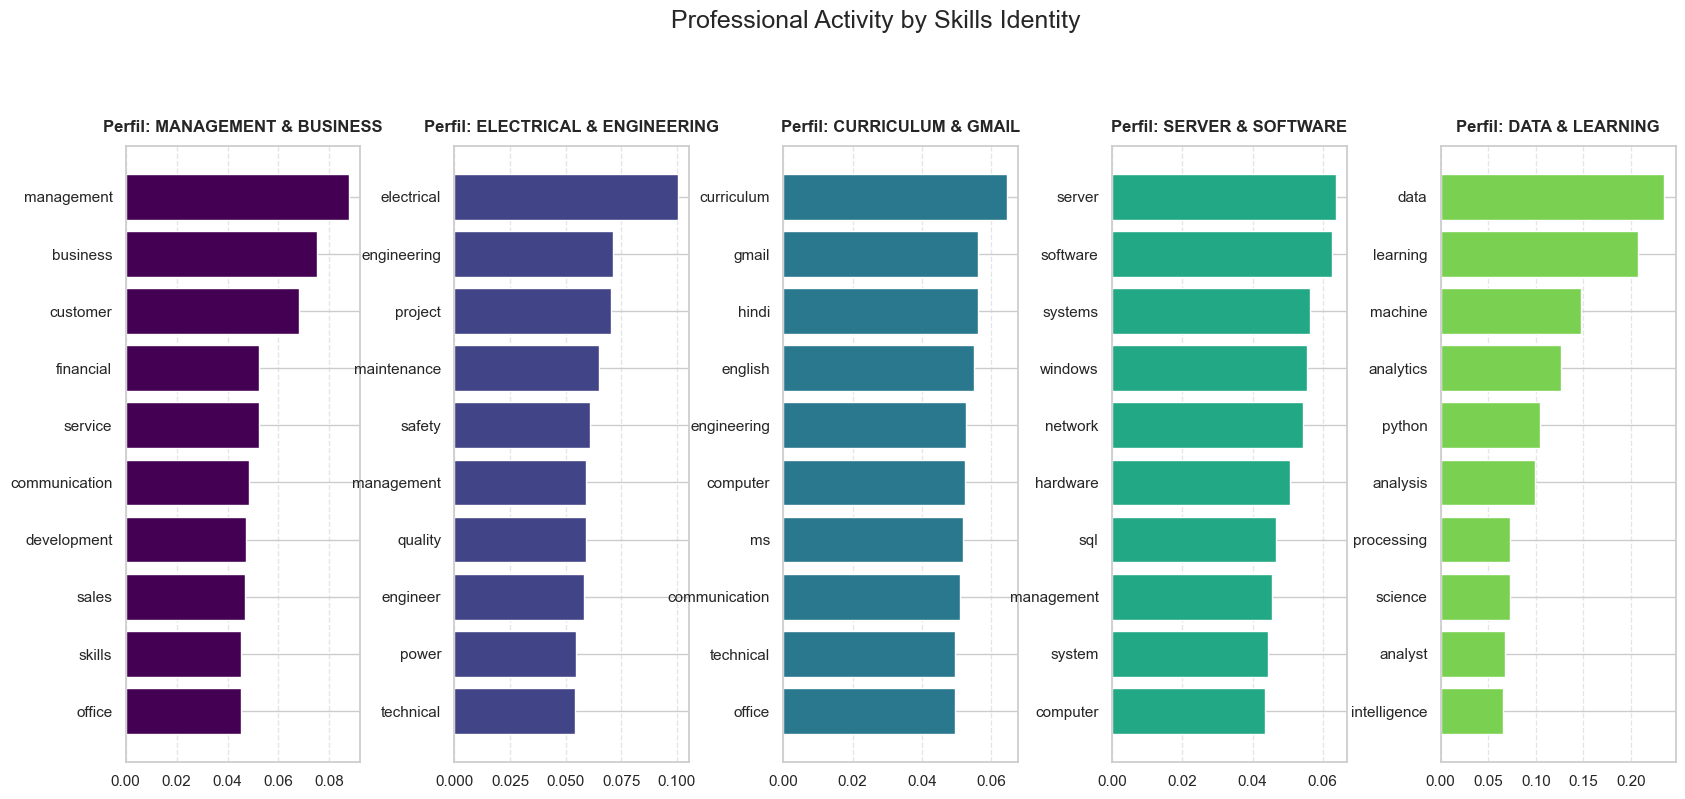

KeyError: 'cluster'

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# 1. Configuração e Treino do Modelo
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)

# ESTA LINHA CRIA A COLUNA 'cluster' - Certifique-se de que o tfidf_matrix existe
df_skills['cluster'] = kmeans.fit_predict(tfidf_matrix)

# 2. Definição dos nomes académicos conforme a sua imagem
mapeamento_perfis = {
    0: "MANAGEMENT & BUSINESS",
    1: "ELECTRICAL & ENGINEERING",
    2: "CURRICULUM & GMAIL",
    3: "SERVER & SOFTWARE",
    4: "DATA & LEARNING"
}

# Criar a coluna de nomes e a coluna de resumo baseada nos centroides
terms = tfidf.get_feature_names_out()
centroids = kmeans.cluster_centers_

df_skills['perfil_nome'] = df_skills['cluster'].map(mapeamento_perfis)

# Esta é a linha que estava a dar erro (agora garantimos que 'cluster' existe)
df_skills['perfil_sugerido'] = df_skills['cluster'].map(
    lambda x: " / ".join([terms[idx] for idx in centroids[x].argsort()[-2:]]).upper()
)

# 3. Visualização PCA com Cores Distintas (Palette 'bright')
pca = PCA(n_components=2)
coords = pca.fit_transform(tfidf_matrix.toarray())
df_skills['pca_x'] = coords[:, 0]
df_skills['pca_y'] = coords[:, 1]

plt.figure(figsize=(12, 8))

# Usamos 'perfil_nome' para a legenda ser informativa
sns.scatterplot(
    data=df_skills, 
    x='pca_x', 
    y='pca_y', 
    hue='perfil_nome', 
    palette='bright', # Cores bem distintas
    alpha=0.8, 
    edgecolor='w',
    s=80 # Pontos ligeiramente maiores
)

plt.title('Skill Space Map: Professional Profile Clustering', fontsize=14, pad=20)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(
    title='Professional Profiles', 
    bbox_to_anchor=(1.05, 1), 
    loc='upper left',
    frameon=True
)

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n✅ DataFrame atualizado com sucesso!")
print(df_skills[['perfil_nome', 'perfil_sugerido']].head())

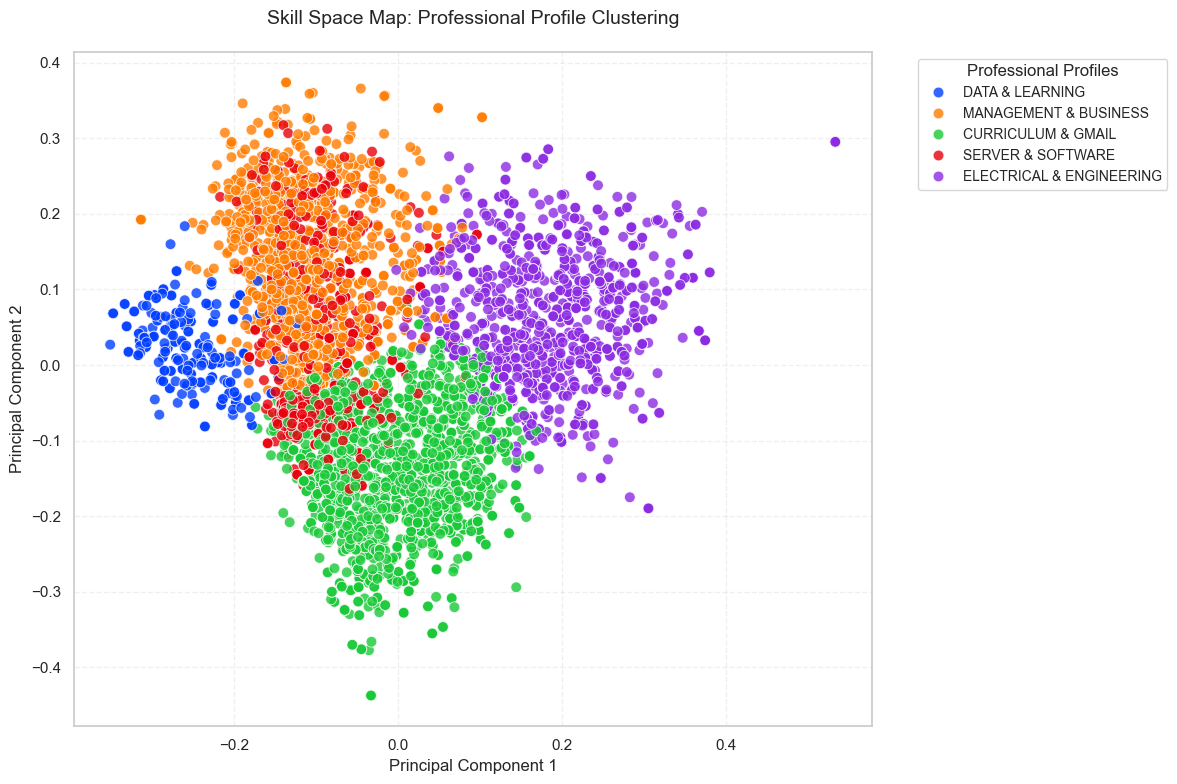

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

mapeamento_perfis = {
    0: "MANAGEMENT & BUSINESS",
    1: "ELECTRICAL & ENGINEERING",
    2: "CURRICULUM & GMAIL",
    3: "SERVER & SOFTWARE",
    4: "DATA & LEARNING"
}

n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df_skills['cluster'] = kmeans.fit_predict(tfidf_matrix)
df_skills['perfil_nome'] = df_skills['cluster'].map(mapeamento_perfis)

pca = PCA(n_components=2)
coords = pca.fit_transform(tfidf_matrix.toarray())
df_skills['pca_x'] = coords[:, 0]
df_skills['pca_y'] = coords[:, 1]

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df_skills, 
    x='pca_x', 
    y='pca_y', 
    hue='perfil_nome', 
    palette='bright', 
    alpha=0.8, 
    edgecolor='w',
    s=60
)

plt.title('Skill Space Map: Professional Profile Clustering', fontsize=14, pad=20)
plt.xlabel('')
plt.ylabel('')

plt.legend(
    title='Professional Profiles', 
    bbox_to_anchor=(1.05, 1), 
    loc='upper left', 
    fontsize=10, 
    title_fontsize=12
)

plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()